In [1]:
from functools import partial
import numpy as np
from datasets import load_dataset
import jax
import jax.numpy as jnp
from model.model import init_model, model_apply


data = load_dataset("uoft-cs/cifar10", split="train")
X_train = np.stack([np.asarray(image) for image in data["img"]])
X_train = X_train.astype(np.float32) / 127.5 - 1

## Flow matching

$$
X_0\sim\mathcal N(0,I),\quad X_1\sim p_{\mathrm{data}},\quad T\sim U[0,1],
$$
$$
X_t=(1-t)X_0+tX_1,\qquad V=X_1-X_0.
$$
$$
\mathcal L(\theta)=\mathbb E\!\left[\frac1{3072}
\left\|v_\theta(X_T,T)-V\right\|^2\right].
$$

[U-Net](model/model.py)

In [2]:
def make_flow_batch(x1, key):
    noise_key, time_key = jax.random.split(key)
    x0 = jax.random.normal(noise_key, x1.shape)
    t = jax.random.uniform(time_key, (len(x1), 1, 1, 1))
    xt = (1 - t) * x0 + t * x1
    return x0, xt, t, x1 - x0

## Training

In [3]:
batch_size = 128
max_epochs = 50
patience = 5
min_delta = 1e-3
lr = 2e-4


def loss_fn(params, xt, t, target):
    prediction = model_apply(params, xt, t)
    return jnp.mean((prediction - target)**2)


@jax.jit
def train_step(params, m, v_adam, xt, t, target, step):
    loss, grads = jax.value_and_grad(loss_fn)(params, xt, t, target)
    m = jax.tree_util.tree_map(lambda a, g: 0.9 * a + 0.1 * g, m, grads)
    v_adam = jax.tree_util.tree_map(
        lambda a, g: 0.999 * a + 0.001 * g**2, v_adam, grads
    )
    params = jax.tree_util.tree_map(
        lambda p, a, b: p - lr * (a / (1 - 0.9**step))
        / (jnp.sqrt(b / (1 - 0.999**step)) + 1e-8),
        params, m, v_adam
    )
    return params, m, v_adam, loss


eval_loss = jax.jit(loss_fn)

In [4]:
key, model_key = jax.random.split(jax.random.key(1))
params = init_model(model_key)
m = jax.tree_util.tree_map(jnp.zeros_like, params)
v_adam = jax.tree_util.tree_map(jnp.zeros_like, params)
step = 0
train_rng = np.random.default_rng(1)

split = np.random.default_rng(2).permutation(len(X_train))
val_indices, train_indices = split[:1024], split[1024:]
val_images = jnp.asarray(X_train[val_indices])
_, val_xt, val_t, val_target = make_flow_batch(val_images, jax.random.key(2))


def validation_loss(params):
    losses = [float(eval_loss(params, val_xt[i:i + batch_size],
                              val_t[i:i + batch_size], val_target[i:i + batch_size]))
              for i in range(0, len(val_images), batch_size)]
    return float(np.mean(losses))


train_losses = []
val_losses = [validation_loss(params)]
if not np.isfinite(val_losses[0]):
    raise FloatingPointError("Non-finite initial validation loss.")
best_loss = patience_loss = val_losses[0]
best_state = (params, m, v_adam, step)
best_epoch = 0
stale_epochs = 0

In [5]:
for epoch in range(max_epochs):
    order = train_rng.permutation(train_indices)
    epoch_loss = 0.0
    batches = len(train_indices) // batch_size

    for start in range(0, batches * batch_size, batch_size):
        step += 1
        batch = jnp.asarray(X_train[order[start:start + batch_size]])
        key, batch_key = jax.random.split(key)
        _, batch_xt, batch_t, batch_target = make_flow_batch(batch, batch_key)
        params, m, v_adam, loss = train_step(
            params, m, v_adam, batch_xt, batch_t, batch_target, step
        )
        epoch_loss += loss

    train_losses.append(float(epoch_loss / batches))
    val_losses.append(validation_loss(params))
    current_loss = val_losses[-1]
    print(f"{epoch + 1:3d} | train {train_losses[-1]:.5f} | validation {current_loss:.5f}")

    if not np.isfinite(train_losses[-1]) or not np.isfinite(current_loss):
        params, m, v_adam, step = best_state
        raise FloatingPointError("Non-finite loss; best training state restored.")

    if current_loss < best_loss:
        best_loss = current_loss
        best_state = (params, m, v_adam, step)
        best_epoch = epoch + 1

    if current_loss < patience_loss - min_delta:
        patience_loss = current_loss
        stale_epochs = 0
    else:
        stale_epochs += 1

    if stale_epochs >= patience:
        print(f"Early stopping at epoch {epoch + 1}.")
        break

params, m, v_adam, step = best_state
print(f"Restored epoch {best_epoch} | validation {best_loss:.5f}")

  1 | train 0.47708 | validation 0.28449


  2 | train 0.26770 | validation 0.24942


  3 | train 0.24662 | validation 0.23453


  4 | train 0.23429 | validation 0.22527


  5 | train 0.22812 | validation 0.22009


  6 | train 0.22143 | validation 0.21450


... (21 outputs left out)

 28 | train 0.19200 | validation 0.18990


 29 | train 0.19062 | validation 0.18855


 30 | train 0.19051 | validation 0.18946


 31 | train 0.19058 | validation 0.18827
Early stopping at epoch 31.
Restored epoch 31 | validation 0.18827


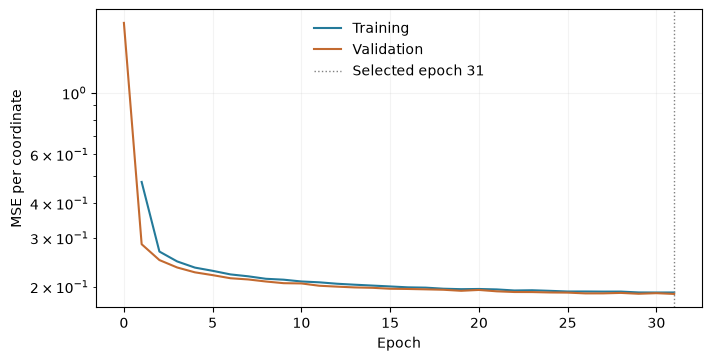

In [6]:
import matplotlib.pyplot as plt


fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.plot(np.arange(1, len(train_losses) + 1), train_losses,
        color="#247a9a", label="Training")
ax.plot(np.arange(len(val_losses)), val_losses,
        color="#c36a30", label="Validation")
ax.axvline(best_epoch, color="0.5", ls=":", lw=1,
           label=f"Selected epoch {best_epoch}")
ax.set(xlabel="Epoch", ylabel="MSE per coordinate", yscale="log")
ax.grid(alpha=0.15)
ax.legend(frameon=False)
plt.show()

## Generation

$$
\dot x=v_\theta(x,t),\qquad x(0)\sim\mathcal N(0,I),
$$
$$
x_{k+1}=x_k+h\,v_\theta(x_k,kh),\qquad h=\frac1{64}.
$$

In [7]:
@partial(jax.jit, static_argnames=("steps",))
def sample(params, noise, steps=64):
    def advance(k, x):
        t = jnp.full((len(x), 1, 1, 1), k / steps)
        return x + model_apply(params, x, t) / steps

    return jax.lax.fori_loop(0, steps, advance, noise)


noise = jax.random.normal(jax.random.key(3), (16, 32, 32, 3))
generated = np.asarray(sample(params, noise))

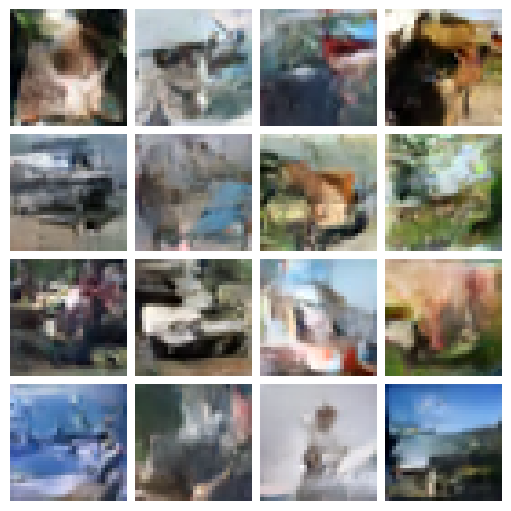

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(5, 5), layout="constrained")
for ax, image in zip(axes.flat, generated):
    ax.imshow(np.clip((image + 1) / 2, 0, 1), interpolation="nearest")
    ax.set_axis_off()
plt.show()